In [1]:
%pip install -q librosa matplotlib soundfile


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display

WAV_PATH = "music.wav"

audio, sr = sf.read(WAV_PATH)

print("Sample rate:", sr)
print("Duration:", round(len(audio) / sr, 2), "seconds")
print("Valid audio:", len(audio) > 0 and np.isfinite(audio).all())

display(Audio(audio.T, rate=sr))

Sample rate: 44100
Duration: 15.0 seconds
Valid audio: True


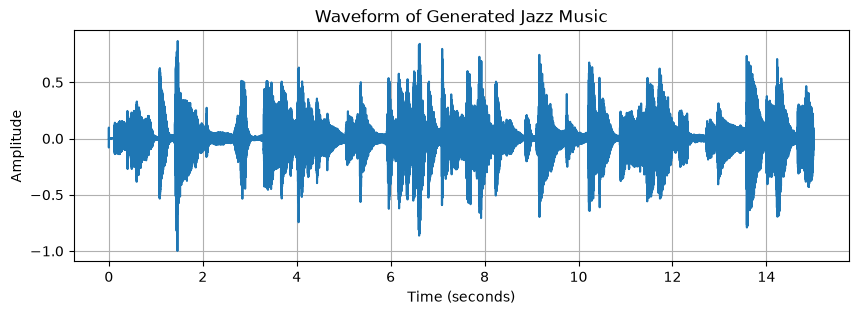

In [3]:
# Convert stereo audio to mono for plotting
mono = audio.mean(axis=1) if audio.ndim == 2 else audio

time_axis = np.arange(len(mono)) / sr

plt.figure(figsize=(10, 3))
plt.plot(time_axis, mono)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Waveform of Generated Jazz Music")
plt.grid()
plt.show()

/Users/aryanahuja/Documents/Aryan/GAI ESE Prac/env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


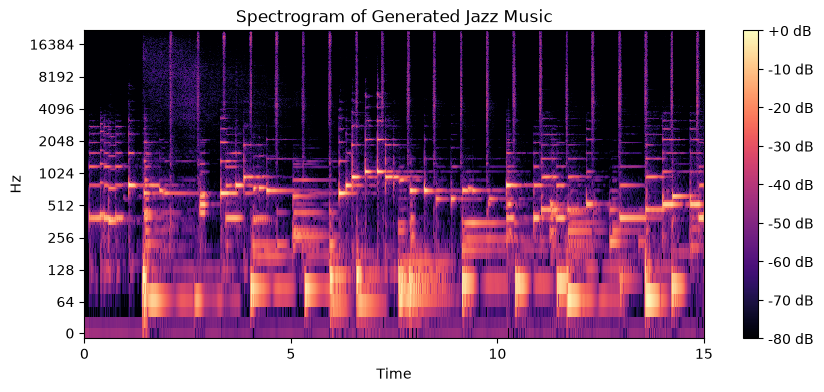

In [4]:
D = librosa.stft(mono)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    S_db,
    sr=sr,
    x_axis="time",
    y_axis="log"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram of Generated Jazz Music")
plt.show()